[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch23_LabCh23_Transformer_Block.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 23: The Transformer Block** (Part V: Attending).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=23](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=23)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch23 - The Transformer Block
## Build one block, count it, give it a sense of order, train it on film reviews, and mask it for a decoder

This lab goes with **Chapter 23** of *The Why Book of Deep Learning*.

A transformer is one block repeated. The block has two sub-layers: multi-head self-attention, where the
tokens talk to each other, and a small feed-forward network, where each token thinks on its own. Round each
sub-layer runs a residual connection, and a LayerNorm keeps the numbers tame. In this lab you build that block
with the Keras Functional API, print the shape at every arrow, check its parameter count against a hand
count, and then find out by experiment why a transformer needs to be told where each word sits.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build a pre-norm transformer block and print the shape at every arrow | Steps 2 and 3 |
| Count its parameters by hand: 3,152,384 at d = 512, ff = 2,048 | Steps 4 to 6 |
| Show that a block without positions is blind to word order | Step 7 |
| Draw sinusoidal position encodings and build learnt position embeddings | Steps 8 to 10 |
| Train a one-block text classifier on IMDB film reviews, with and without positions | Steps 11 to 15 |
| Build a task that is impossible without positions, and watch positions solve it | Steps 16 to 18 |
| Make the causal mask of a decoder and prove it hides the future | Steps 19 to 21 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** one to three minutes on a laptop CPU (under one minute on the machine it was tested on), plus
> the TensorFlow import (a minute or two the first time). To keep it that short the lab uses a **subset** of IMDB (10,000 training reviews, 5,000 test
> reviews), a 5,000-word vocabulary, reviews cut to 128 tokens, a tiny width (d = 32) and 3 epochs.
> For a real run use all 25,000 reviews, 20,000 words, 256 to 512 tokens, d = 128 and 10 epochs or more.
> IMDB is downloaded once by `keras.datasets` (about 17 MB); if the download fails the lab falls back to a
> synthetic task and says so.

---
# Part A - One block, shape by shape

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(23)
np.set_printoptions(precision=3, suppress=True)
T0 = time.time()
print("Keras:", keras.__version__)

Keras: 3.14.1


---
## Step 2 - The block as a function

This is the **pre-norm** block, the modern default: normalise *before* each sub-layer, and add the
sub-layer's output back onto the untouched input (the residual stream).

```
x ──► LayerNorm ──► MultiHeadAttention ──► (+ x) ──► LayerNorm ──► Dense(ff, relu) ──► Dense(d) ──► (+) ──► out
 └──────────────── residual ──────────────┘ └──────────────────── residual ─────────────────────┘
```

The function prints the shape of the tensor on every arrow when `verbose=True`.

> **Predict:** which arrows change the shape? (Hint: only one sub-layer goes wider than d.)

In [2]:
def transformer_block(x, d, heads, ff, dropout=0.0, causal=False, name="block", verbose=False):
    """Pre-norm transformer block: x + MHA(LN(x)), then + FFN(LN(.)). Input and output are (batch, T, d)."""
    say = (lambda tag, t: print(f"  {tag:<34s} {str(t.shape)}")) if verbose else (lambda tag, t: None)
    say("in", x)
    h = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x);               say("LayerNorm 1", h)
    h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=dropout,
                                  name=f"{name}_mha")(h, h, use_causal_mask=causal);   say("MultiHeadAttention (self)", h)
    h = layers.Dropout(dropout, name=f"{name}_drop1")(h)
    x = layers.Add(name=f"{name}_add1")([x, h]);                                       say("Add (residual 1)", x)
    h = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x);               say("LayerNorm 2", h)
    h = layers.Dense(ff, activation="relu", name=f"{name}_ff1")(h);                   say(f"Dense({ff}, relu)  (the one wide arrow)", h)
    h = layers.Dense(d, name=f"{name}_ff2")(h);                                       say(f"Dense({d})", h)
    h = layers.Dropout(dropout, name=f"{name}_drop2")(h)
    x = layers.Add(name=f"{name}_add2")([x, h]);                                       say("Add (residual 2)  = out", x)
    return x

print("defined transformer_block(x, d, heads, ff, ...)")

defined transformer_block(x, d, heads, ff, ...)


---
## Step 3 - Build it at the size of the original paper

Width d = 512, 8 heads (so each head works on 512 / 8 = 64 numbers), feed-forward width 2,048, and a
sequence of T = 10 tokens. The batch size is left open (`None`).

> **Predict:** the shape that comes out of the block.

In [3]:
d, heads, ff, T = 512, 8, 2048, 10
inp = layers.Input(shape=(T, d), name="tokens")
print("Shapes at every arrow:")
out = transformer_block(inp, d, heads, ff, verbose=True)
block = keras.Model(inp, out, name="one_block")

Shapes at every arrow:
  in                                 (None, 10, 512)
  LayerNorm 1                        (None, 10, 512)
  MultiHeadAttention (self)          (None, 10, 512)
  Add (residual 1)                   (None, 10, 512)
  LayerNorm 2                        (None, 10, 512)
  Dense(2048, relu)  (the one wide arrow) (None, 10, 2048)
  Dense(512)                         (None, 10, 512)
  Add (residual 2)  = out            (None, 10, 512)


### Why we see this

The shape that leaves the block, `(None, 10, 512)`, is the shape that entered it. That is the whole reason a
transformer can be a tower: the output of block 1 is a perfectly good input for block 2, and so on for 12,
24 or 96 floors. Only one arrow changes the shape: the first feed-forward `Dense` widens every token to 2,048
numbers, and the second brings it straight back. Attention mixes information *between* the 10 positions but
never changes how many numbers each position carries.

---
## Step 4 - Count the parameters by hand

* **Attention:** four d × d projections (query, key, value, output), each with d biases: 4·(d² + d).
* **Feed-forward:** d × ff weights + ff biases, then ff × d weights + d biases.
* **Two LayerNorms:** each has a scale and a shift per feature: 2·d each.

> **Predict:** write the three numbers and the total before you run the cell.

In [4]:
attn = 4 * (d * d + d)
ffn = (d * ff + ff) + (ff * d + d)
norms = 2 * (2 * d)
hand = attn + ffn + norms
print(f"attention     4·(d² + d)          = {attn:>10,}")
print(f"feed-forward  d·ff + ff + ff·d + d = {ffn:>10,}")
print(f"LayerNorms    2 × 2d               = {norms:>10,}")
print(f"total (hand)                       = {hand:>10,}")
print(f"Keras count_params()               = {block.count_params():>10,}")
assert block.count_params() == hand == 3_152_384
print(f"\nfeed-forward share: {ffn / hand:.1%}   attention share: {attn / hand:.1%}")

attention     4·(d² + d)          =  1,050,624
feed-forward  d·ff + ff + ff·d + d =  2,099,712
LayerNorms    2 × 2d               =      2,048
total (hand)                       =  3,152,384
Keras count_params()               =  3,152,384

feed-forward share: 66.6%   attention share: 33.3%


---
## Step 5 - Check it layer by layer

`count_params()` agreeing with the total could hide two errors that cancel. Print each layer's own count.

> **Predict:** how many parameters do the `Add` and `Dropout` layers have?

In [5]:
for layer in block.layers:
    if layer.count_params() or isinstance(layer, (layers.Add, layers.Dropout)):
        print(f"{layer.name:<14s} {type(layer).__name__:<20s} {layer.count_params():>10,}")
mha = block.get_layer("block_mha")
print("\nMHA weight shapes:", [tuple(w.shape) for w in mha.weights][:4], "...")

block_ln1      LayerNormalization        1,024
block_mha      MultiHeadAttention    1,050,624
block_drop1    Dropout                       0
block_add1     Add                           0
block_ln2      LayerNormalization        1,024
block_ff1      Dense                 1,050,624
block_ff2      Dense                 1,049,088
block_drop2    Dropout                       0
block_add2     Add                           0

MHA weight shapes: [(512, 8, 64), (8, 64), (512, 8, 64), (8, 64)] ...


### Why we see this

The residual `Add` and the `Dropout` own nothing: adding two tensors and switching numbers off have no knobs.
The attention layer stores its query kernel as `(512, 8, 64)`: 8 heads of 64 numbers each, which is still a
512 × 512 matrix cut into 8 slices. That is why the count does not depend on the number of heads. It does not
depend on T either: the same weights serve a sentence of 10 tokens or 10,000. And **two thirds** of the block
is the plain feed-forward network (Chapter 24 is about that quiet half).

---
## Step 6 - Stack six blocks, and try post-norm

Pre-norm leaves the residual stream un-normalised all the way up, so a pre-norm stack needs **one final
LayerNorm** after the last block. Post-norm (the 2017 original) puts the norm *after* each addition instead.

> **Predict:** the parameter count of 6 pre-norm blocks plus a final norm. And: does post-norm change the count?

In [6]:
def post_norm_block(x, d, heads, ff, name="post"):
    h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, name=f"{name}_mha")(x, x)
    x = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(layers.Add()([x, h]))      # norm AFTER the add
    h = layers.Dense(d, name=f"{name}_ff2")(layers.Dense(ff, activation="relu", name=f"{name}_ff1")(x))
    return layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(layers.Add()([x, h]))

x = inp6 = layers.Input(shape=(T, d))
for i in range(6):
    x = transformer_block(x, d, heads, ff, name=f"b{i}")
x = layers.LayerNormalization(epsilon=1e-6, name="final_ln")(x)
six = keras.Model(inp6, x)
print(f"6 pre-norm blocks + final norm: {six.count_params():,}   (hand: 6 × {hand:,} + {2 * d:,})")
assert six.count_params() == 6 * hand + 2 * d

inp_p = layers.Input(shape=(T, d))
post = keras.Model(inp_p, post_norm_block(inp_p, d, heads, ff))
print(f"one post-norm block:            {post.count_params():,}")
assert post.count_params() == hand

6 pre-norm blocks + final norm: 18,915,328   (hand: 6 × 3,152,384 + 1,024)
one post-norm block:            3,152,384


### Why we see this

6 × 3,152,384 + 1,024 = 18,915,328: about 18.9 million parameters before a single word has been embedded.
Post-norm has exactly the same weights; only the wiring differs. The difference shows up in training, not in
the count: in post-norm every signal and every gradient must pass through a LayerNorm on every floor, while
pre-norm leaves a clean addition-only path from the top of the tower to the bottom. That is why deep post-norm
stacks need a careful learning-rate warm-up and pre-norm stacks are more forgiving.

---
# Part B - Positions

---
## Step 7 - The block cannot see word order

Feed the block a sequence, then the same sequence with its tokens shuffled.

> **Predict:** is the second output (a) completely different, (b) the first output shuffled the same way,
> or (c) identical to the first?

In [7]:
rng = np.random.default_rng(23)
xs = rng.normal(size=(1, T, d)).astype("float32")
perm = rng.permutation(T)
y_plain = block.predict(xs, verbose=0)
y_shuf = block.predict(xs[:, perm], verbose=0)
print("permutation:", perm)
print("output of shuffled input == shuffled output?", np.allclose(y_shuf, y_plain[:, perm], atol=1e-4))
print("largest difference:", float(np.abs(y_shuf - y_plain[:, perm]).max()))

permutation: [4 5 1 3 9 0 8 2 6 7]
output of shuffled input == shuffled output? True
largest difference: 7.152557373046875e-07


### Why we see this

Answer (b). Attention scores every token against every other with dot products, and nothing in a dot product
knows *where* a token sits. The feed-forward part treats each token on its own. So shuffling the input only
shuffles the output (the jargon is *permutation-equivariant*). Average the outputs, as a classifier does, and
the shuffle disappears completely: to such a model, "the dog bit the man" and "the man bit the dog" are the
same bag of words. Positions must be added to the input.

---
## Step 8 - Sinusoidal position encodings

The 2017 recipe: give position *p* a vector of d numbers made of sine and cosine waves. Pair *i* uses the
wavelength 2π · 10000^(2i/d), so the first pairs wiggle fast (they tell neighbours apart) and the last pairs
change very slowly (they say roughly where in a long text you are). The vector is **added** to the token
embedding.

> **Predict:** in the heat map (rows = positions, columns = features), where will the stripes be narrow and
> where wide?

sinusoidal table: (128, 64)   values between -1.0 and 1.0


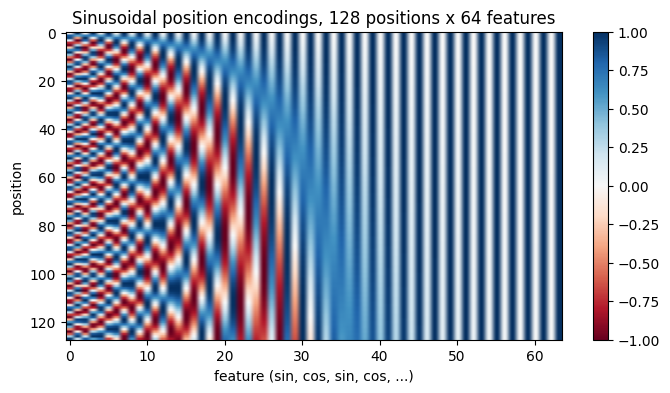

In [8]:
def sinusoidal(max_len, d):
    pos = np.arange(max_len)[:, None]
    i = np.arange(d // 2)[None, :]
    angle = pos / np.power(10000.0, 2 * i / d)
    pe = np.zeros((max_len, d), dtype="float32")
    pe[:, 0::2] = np.sin(angle)
    pe[:, 1::2] = np.cos(angle)
    return pe

pe = sinusoidal(128, 64)
print("sinusoidal table:", pe.shape, "  values between", pe.min().round(3), "and", pe.max().round(3))
plt.figure(figsize=(8, 4))
plt.imshow(pe, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
plt.xlabel("feature (sin, cos, sin, cos, ...)"); plt.ylabel("position"); plt.colorbar()
plt.title("Sinusoidal position encodings, 128 positions x 64 features")
plt.show()

### Why we see this

The left-hand columns flip between +1 and -1 every few positions: narrow stripes. Moving right, the waves
slow down until the last columns barely change across all 128 positions. Every row is different, so every
position gets its own fingerprint, and nothing here is learnt: the table is fixed, costs 0 parameters, and can
be computed for any position, even ones longer than anything seen in training (whether the model then *uses*
them well is another matter).

---
## Step 9 - Similar positions have similar codes

Take the dot product of position 40's code with every other position's code.

> **Predict:** where is the peak, and does the curve depend on *which* position you pick, or only on the
> distance?

peak of position 40's row at: 40   value: 32.0 (= d/2)
40 vs 45: 23.504    90 vs 95: 23.504    (same distance, same score)


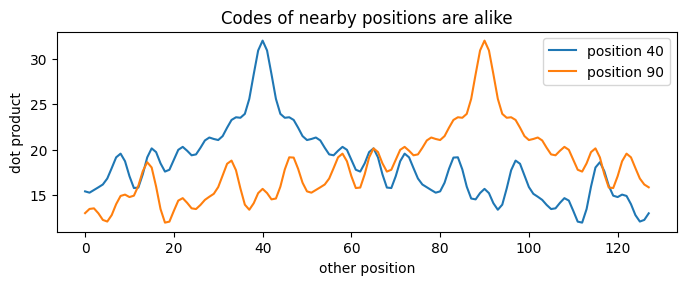

In [9]:
sim40 = pe @ pe[40]
sim90 = pe @ pe[90]
print("peak of position 40's row at:", int(sim40.argmax()), "  value:", sim40.max().round(2), "(= d/2)")
print("40 vs 45:", sim40[45].round(3), "   90 vs 95:", sim90[95].round(3), "   (same distance, same score)")
plt.figure(figsize=(8, 2.6))
plt.plot(sim40, label="position 40"); plt.plot(sim90, label="position 90"); plt.legend()
plt.xlabel("other position"); plt.ylabel("dot product"); plt.title("Codes of nearby positions are alike")
plt.show()

### Why we see this

The dot product of two sinusoidal codes depends only on how far apart the positions are (it is a sum of
cosines of the distance times each frequency). Distance 5 scores the same at 40 and at 90. That is the
property that rotary embeddings (RoPE, in the chapter) build into the attention scores directly.

---
## Step 10 - Learnt position embeddings

The other common choice: a second lookup table of shape `(max_len, d)`, trained like the word embeddings.
Position 0 looks up row 0, position 1 row 1, and so on. Keras has no built-in layer for this, so we write a
four-line one.

> **Predict:** its parameter count for max_len = 128, d = 32. What happens if a sequence of 129 tokens arrives?

In [10]:
class PositionEmbedding(layers.Layer):
    """Adds a learnt vector for each position 0..max_len-1 to the input (batch, T, d)."""
    def __init__(self, max_len, d, **kw):
        super().__init__(**kw)
        self.table = layers.Embedding(max_len, d)
    def call(self, x):
        positions = keras.ops.arange(keras.ops.shape(x)[1])
        return x + self.table(positions)          # (T, d) broadcasts over the batch

pos_layer = PositionEmbedding(128, 32)
print("output shape:", pos_layer(np.zeros((2, 128, 32), "float32")).shape, "  params:", pos_layer.count_params())
assert pos_layer.count_params() == 128 * 32

output shape: (2, 128, 32)   params: 4096


128 × 32 = 4,096 parameters. A 129th token would ask for row 128, which does not exist: a learnt table simply
has no answer past `max_len` (on a GPU the lookup may even return zeros silently instead of failing). That is
the price of learning the table instead of computing it.

---
# Part C - A one-block classifier on IMDB

---
## Step 11 - Load a subset of IMDB

50,000 film reviews labelled positive (1) or negative (0). Each review is already a list of word indices,
most frequent words first. We keep the 5,000 most common words, cut or pad every review to 128 tokens, and
use 10,000 reviews for training and 5,000 for testing. Index 0 is padding.

> **Predict:** what fraction of the test reviews is positive?

In [11]:
VOCAB, MAXLEN, N_TRAIN, N_TEST = 5000, 128, 10_000, 5_000
try:
    (x_tr, y_tr), (x_te, y_te) = keras.datasets.imdb.load_data(num_words=VOCAB)
    DATA = "IMDB"
except Exception as e:                       # no internet: a synthetic stand-in with the same shapes
    print("IMDB download failed:", repr(e)[:120], "\n-> using a SYNTHETIC task instead (results will differ)")
    DATA = "synthetic"
    r = np.random.default_rng(0)
    def fake(n):
        y = r.integers(0, 2, n)
        x = [list(r.integers(3, VOCAB, r.integers(40, 200))) + [10 + int(t)] * 5 for t in y]
        return x, y
    (x_tr, y_tr), (x_te, y_te) = fake(25_000), fake(25_000)

idx_tr = np.random.default_rng(1).permutation(len(x_tr))[:N_TRAIN]
idx_te = np.random.default_rng(2).permutation(len(x_te))[:N_TEST]
pad = lambda seqs: keras.utils.pad_sequences(seqs, maxlen=MAXLEN, padding="post", truncating="post")
Xtr, Ytr = pad([x_tr[i] for i in idx_tr]), np.asarray(y_tr)[idx_tr]
Xte, Yte = pad([x_te[i] for i in idx_te]), np.asarray(y_te)[idx_te]
print(f"data: {DATA}   train {Xtr.shape}   test {Xte.shape}   positive share in test: {Yte.mean():.3f}")
print("first review, first 12 word indices:", Xtr[0, :12])

data: IMDB   train (10000, 128)   test (5000, 128)   positive share in test: 0.499
first review, first 12 word indices: [   1 4089 2107 1768    2 1792    5 2273    2   26  289 1340]


---
## Step 12 - The classifier

Token embedding (5,000 × 32) → **plus** position embedding (128 × 32) → one pre-norm block → final LayerNorm
→ average over the 128 positions → one sigmoid unit. Small width: d = 32, 2 heads of 16, ff = 64.

(A real model would also pass a **padding mask** so that attention ignores the zeros at the end of short
reviews; Chapter 22 shows how. We leave it out here to keep the model short.)

> **Predict:** the total parameter count. Write the five pieces first.

In [12]:
D, HEADS, FF = 32, 2, 64

def make_classifier(n_blocks=1, positions=True, vocab=VOCAB, max_len=MAXLEN, name="clf"):
    tok = layers.Input(shape=(max_len,), dtype="int32", name="word_ids")
    x = layers.Embedding(vocab, D, name="word_embedding")(tok)            # (batch, T, d)
    if positions:
        x = PositionEmbedding(max_len, D, name="position_embedding")(x)     # same shape, now order-aware
    for b in range(n_blocks):
        x = transformer_block(x, D, HEADS, FF, dropout=0.1, name=f"blk{b}")
    x = layers.LayerNormalization(epsilon=1e-6, name="final_ln")(x)         # pre-norm needs a final norm
    x = layers.GlobalAveragePooling1D(name="average")(x)                    # (batch, d)
    out = layers.Dense(1, activation="sigmoid", name="positive")(x)
    return keras.Model(tok, out, name=name)

def hand_count(n_blocks, positions, vocab=VOCAB, max_len=MAXLEN):
    block = 4 * (D * D + D) + (D * FF + FF) + (FF * D + D) + 2 * 2 * D
    return vocab * D + (max_len * D if positions else 0) + n_blocks * block + 2 * D + (D + 1)

clf = make_classifier(1, True, name="with_positions")
clf.summary(line_length=88)
print(f"hand count: {hand_count(1, True):,}")
assert clf.count_params() == hand_count(1, True)

Model: "with_positions"

┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)            ┃ Output Shape         ┃      Param # ┃ Connected to         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ word_ids (InputLayer)   │ (None, 128)          │            0 │ -                    │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ word_embedding          │ (None, 128, 32)      │      160,000 │ word_ids[0][0]       │
│ (Embedding)             │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ position_embedding      │ (None, 128, 32)      │        4,096 │ word_embedding[0][0] │
│ (PositionEmbedding)     │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_ln1                │ (None, 128, 32)      │           64 │ position_embedding[… │
│ (LayerNormalization)    │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_mha                │ (None, 128, 32)      │        4,224 │ blk0_ln1[0][0],      │
│ (MultiHeadAttention)    │                      │              │ blk0_ln1[0][0]       │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_drop1 (Dropout)    │ (None, 128, 32)      │            0 │ blk0_mha[0][0]       │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_add1 (Add)         │ (None, 128, 32)      │            0 │ position_embedding[… │
│                         │                      │              │ blk0_drop1[0][0]     │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_ln2                │ (None, 128, 32)      │           64 │ blk0_add1[0][0]      │
│ (LayerNormalization)    │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_ff1 (Dense)        │ (None, 128, 64)      │        2,112 │ blk0_ln2[0][0]       │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_ff2 (Dense)        │ (None, 128, 32)      │        2,080 │ blk0_ff1[0][0]       │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_drop2 (Dropout)    │ (None, 128, 32)      │            0 │ blk0_ff2[0][0]       │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ blk0_add2 (Add)         │ (None, 128, 32)      │            0 │ blk0_add1[0][0],     │
│                         │                      │              │ blk0_drop2[0][0]     │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ final_ln                │ (None, 128, 32)      │           64 │ blk0_add2[0][0]      │
│ (LayerNormalization)    │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ average                 │ (None, 32)           │            0 │ final_ln[0][0]       │
│ (GlobalAveragePooling1… │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ positive (Dense)        │ (None, 1)            │           33 │ average[0][0]        │
└─────────────────────────┴──────────────────────┴──────────────┴──────────────────────┘

 Total params: 172,737 (674.75 KB)

 Trainable params: 172,737 (674.75 KB)

 Non-trainable params: 0 (0.00 B)

hand count: 172,737


### Why we see this

160,000 + 4,096 + 8,544 + 64 + 33 = 172,737. The word table holds 93% of the model; the transformer block
itself is only 8,544 parameters at this width. Small models are dominated by their embeddings. In big
language models it flips: the blocks grow with d², the embedding only with d.

---
## Step 13 - Train it, with positions

Three epochs, Adam (AdamW and warm-up are what large models use; a model this small does not need them).

> **Predict:** test accuracy after three epochs. Above or below 80%?

In [13]:
def train(model, X, Y, epochs=3):
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    t = time.time()
    h = model.fit(X, Y, validation_split=0.1, epochs=epochs, batch_size=64, verbose=2)
    print(f"trained in {time.time() - t:.0f}s")
    return h

h_pos = train(clf, Xtr, Ytr)
acc_pos = clf.evaluate(Xte, Yte, verbose=0)[1]
print(f"\nTEST accuracy WITH positions: {acc_pos:.3f}")

Epoch 1/3


141/141 - 6s - 46ms/step - accuracy: 0.7309 - loss: 0.5104 - val_accuracy: 0.8330 - val_loss: 0.3759


Epoch 2/3


141/141 - 4s - 27ms/step - accuracy: 0.8894 - loss: 0.2765 - val_accuracy: 0.8110 - val_loss: 0.4719


Epoch 3/3


141/141 - 4s - 27ms/step - accuracy: 0.9360 - loss: 0.1755 - val_accuracy: 0.7990 - val_loss: 0.5919


trained in 14s



TEST accuracy WITH positions: 0.783


---
## Step 14 - The same model with the positions removed

Identical except that the `PositionEmbedding` layer is gone. The model now sees a bag of words.

> **Predict:** how much test accuracy do we lose? 1 point? 10? 30?

In [14]:
keras.utils.set_random_seed(23)
clf_nopos = make_classifier(1, False, name="no_positions")
assert clf_nopos.count_params() == hand_count(1, False)
print(f"params without positions: {clf_nopos.count_params():,}")
h_nopos = train(clf_nopos, Xtr, Ytr)
acc_nopos = clf_nopos.evaluate(Xte, Yte, verbose=0)[1]
print(f"\nTEST accuracy WITH positions:    {acc_pos:.3f}")
print(f"TEST accuracy WITHOUT positions: {acc_nopos:.3f}")

params without positions: 168,641
Epoch 1/3


141/141 - 6s - 46ms/step - accuracy: 0.7106 - loss: 0.5340 - val_accuracy: 0.8130 - val_loss: 0.3996


Epoch 2/3


141/141 - 4s - 27ms/step - accuracy: 0.8811 - loss: 0.2929 - val_accuracy: 0.8140 - val_loss: 0.4689


Epoch 3/3


141/141 - 4s - 27ms/step - accuracy: 0.9184 - loss: 0.2143 - val_accuracy: 0.8040 - val_loss: 0.5893


trained in 14s



TEST accuracy WITH positions:    0.783
TEST accuracy WITHOUT positions: 0.785


### Why we see this

First, look at the training logs of both runs: training accuracy keeps climbing while `val_accuracy` peaks
after the first or second epoch and then slips. With only 10,000 reviews even a 170,000-parameter model starts
to memorise; for a real run you would add data, early stopping (Chapter 12) or more dropout.

Second, the two test accuracies are close, within a point or two (the exact numbers vary from run to run). That surprises
most people, and it is a real lesson: **film-review sentiment is mostly a bag-of-words problem.** "Brilliant",
"awful" and "waste" carry the verdict wherever they sit, which is why simple word-count models do well on IMDB
too. The test you choose decides whether you can see a missing ingredient at all. Step 15 proves the
no-position model really is order-blind; Steps 16 to 18 use a task where order is everything.

---
## Step 15 - Shuffle every review and ask both models again

Shuffle the 128 tokens of every test review (padding included) at random.

> **Predict:** how many predictions change for each model?

In [15]:
rng = np.random.default_rng(5)
Xshuf = np.array([row[rng.permutation(MAXLEN)] for row in Xte[:1000]])
for m in (clf, clf_nopos):
    p0 = m.predict(Xte[:1000], verbose=0).ravel()
    p1 = m.predict(Xshuf, verbose=0).ravel()
    flips = int(((p0 > 0.5) != (p1 > 0.5)).sum())
    print(f"{m.name:<15s} largest change in probability {np.abs(p0 - p1).max():.5f}   decisions flipped: {flips} / 1000")

with_positions  largest change in probability 0.94382   decisions flipped: 106 / 1000


no_positions    largest change in probability 0.00000   decisions flipped: 0 / 1000


### Why we see this

The model without positions gives the same answer for a review and for word salad made from it (any change is
floating-point rounding). The model with positions changes its answers, because word order is now part of its
input, even though it gained little accuracy from it on this task.

---
## Step 16 - A task that is impossible without positions

Each sequence has 16 tokens: random filler words (ids 3 to 19) with token **1** and token **2** each placed
once at random. The label is 1 if token 1 comes **before** token 2.

> **Predict:** the best accuracy a model *without* positions can possibly reach. Why?

In [16]:
def order_task(n, length=16, seed=0):
    r = np.random.default_rng(seed)
    X = r.integers(3, 20, size=(n, length))
    Y = np.zeros(n, dtype="int64")
    for k in range(n):
        a, b = r.choice(length, 2, replace=False)
        X[k, a], X[k, b] = 1, 2
        Y[k] = int(a < b)
    return X.astype("int32"), Y

Xo, Yo = order_task(8000, seed=0)
Xo_te, Yo_te = order_task(2000, seed=1)
print(Xo[:3], Yo[:3])

[[17 13 11  7  8  3  2  3  5 16  1 18 11 13 19 15]
 [13 12 12 18  7 16 14  1  9  2 12  3 16 15 17  5]
 [ 4 17  3  1  4  8 11 10  9  3  3  5  3  2 11 14]] [0 1 1]


For every sequence with label 1 there is an equally likely sequence holding exactly the same tokens with label
0 (swap the places of 1 and 2). Without positions the two are identical inputs, so no model can beat 50%.

---
## Step 17 - Train both on the order task

> **Predict:** test accuracy with and without positions after 8 epochs.

In [17]:
results = {}
for use_pos in (True, False):
    keras.utils.set_random_seed(23)
    m = make_classifier(1, use_pos, vocab=20, max_len=16, name="order_pos" if use_pos else "order_nopos")
    m.compile(optimizer=keras.optimizers.Adam(2e-3), loss="binary_crossentropy", metrics=["accuracy"])
    m.fit(Xo, Yo, epochs=8, batch_size=64, verbose=0)
    results[use_pos] = (m, m.evaluate(Xo_te, Yo_te, verbose=0)[1])
    print(f"positions={use_pos!s:<5}  test accuracy {results[use_pos][1]:.3f}")
order_model = results[True][0]

positions=True   test accuracy 1.000


positions=False  test accuracy 0.497


### Why we see this

Without positions the model sits at about 50%, as the argument above promised: no amount of training can
help. With a 16 × 32 table of learnt positions (512 parameters) it solves most of the task in a few epochs.
Same blocks, same data; the only difference is whether the input carries a sense of *where*.

---
## Step 18 - What did the position table learn?

Compare every learnt position vector with every other (cosine similarity).

> **Predict:** will neighbouring positions end up similar, as the sinusoidal ones are by design?

table shape: (16, 32)   mean similarity of neighbours: 0.569   of positions 8+ apart: -0.357


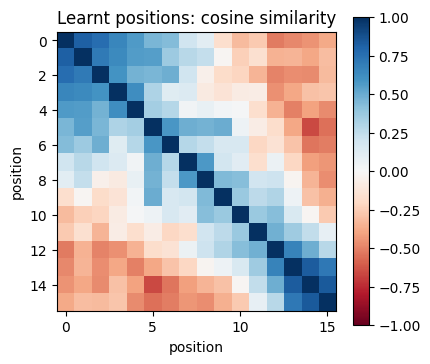

In [18]:
P = order_model.get_layer("position_embedding").table.get_weights()[0]       # (16, 32)
Pn = P / np.linalg.norm(P, axis=1, keepdims=True)
cos = Pn @ Pn.T
print("table shape:", P.shape, "  mean similarity of neighbours:",
      np.mean([cos[i, i + 1] for i in range(15)]).round(3), "  of positions 8+ apart:",
      np.mean([cos[i, j] for i in range(16) for j in range(16) if abs(i - j) >= 8]).round(3))
plt.figure(figsize=(4.5, 4))
plt.imshow(cos, cmap="RdBu", vmin=-1, vmax=1); plt.colorbar()
plt.title("Learnt positions: cosine similarity"); plt.xlabel("position"); plt.ylabel("position")
plt.show()

### Why we see this

The table started as random numbers with no notion of "near". Training shaped it only because the task needed
"earlier" and "later": in our run neighbouring positions ended up clearly alike (cosine about 0.57) and
positions eight or more apart pointed in roughly opposite directions (about -0.36). Nobody told the model that
position 5 is next to position 6; it discovered it. The picture is noisier on a small task than in large
language models, whose learnt position tables come out smooth and banded. The
expert's reading: learnt tables can fit the data better, fixed or rotary schemes generalise to new lengths
better.

---
# Part D - The decoder's causal mask

---
## Step 19 - The mask itself

A decoder (a GPT-style model) predicts the next token at every position at once. Position *t* must not see
positions after *t*, or it could copy the answer. The causal mask allows row *t* to attend to columns 0..*t*.

> **Predict:** for T = 8, how many of the 64 query-key pairs are allowed?

[[1 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0]
 [1 1 1 0 0 0 0 0]
 [1 1 1 1 0 0 0 0]
 [1 1 1 1 1 0 0 0]
 [1 1 1 1 1 1 0 0]
 [1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1]]
allowed pairs: 36 of 64   = T(T+1)/2 = 36


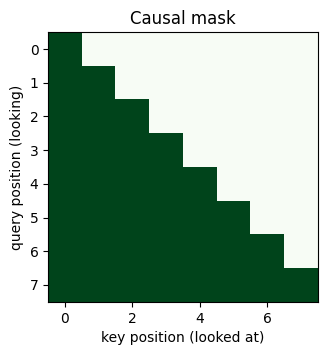

In [19]:
Tm = 8
causal = np.tril(np.ones((Tm, Tm), dtype=int))
print(causal)
print("allowed pairs:", causal.sum(), "of", Tm * Tm, "  = T(T+1)/2 =", Tm * (Tm + 1) // 2)
plt.figure(figsize=(3.5, 3.5))
plt.imshow(causal, cmap="Greens"); plt.xlabel("key position (looked at)"); plt.ylabel("query position (looking)")
plt.title("Causal mask"); plt.show()

---
## Step 20 - Prove that it hides the future

Build a small decoder block (`use_causal_mask=True`) and an encoder block (no mask). Change only the **last**
token of the input.

> **Predict:** for each block, which output positions change?

In [20]:
keras.utils.set_random_seed(23)
inp_d = layers.Input(shape=(Tm, 16))
dec = keras.Model(inp_d, transformer_block(inp_d, 16, 2, 32, causal=True, name="dec"))
enc = keras.Model(inp_d, transformer_block(inp_d, 16, 2, 32, causal=False, name="enc"))
a = np.random.default_rng(3).normal(size=(1, Tm, 16)).astype("float32")
b = a.copy()
b[0, -1] = np.random.default_rng(4).normal(size=16)   # replace only the last token
# (adding a constant such as +5 to every feature would NOT work: LayerNorm removes the mean first!)
for name, m in (("decoder (causal)", dec), ("encoder (no mask)", enc)):
    diff = np.abs(m.predict(a, verbose=0) - m.predict(b, verbose=0)).max(axis=-1)[0]
    print(f"{name:<18s} change at each position: {np.round(diff, 4)}")

decoder (causal)   change at each position: [0.    0.    0.    0.    0.    0.    0.    2.553]
encoder (no mask)  change at each position: [0.087 0.1   0.119 0.112 0.078 0.082 0.099 2.974]


### Why we see this

In the decoder only the last position changes: no earlier position could see the token that was edited. In
the encoder every position changes, because every token attends to every other. This is what lets a decoder
**train on all T positions in parallel** (teacher forcing for free): each position's prediction is computed
from the past only, even though the whole sentence is fed in at once.

---
## Step 21 - What a language model's output looks like

A decoder-only language model ends with `Dense(vocab)` on every position: one score per word in the
vocabulary, at every position, for the next token.

> **Predict:** the output shape for a batch of 4 sequences of 8 tokens with a 1,000-word vocabulary.

In [21]:
tok_in = layers.Input(shape=(Tm,), dtype="int32")
h = PositionEmbedding(Tm, 16)(layers.Embedding(1000, 16)(tok_in))
h = transformer_block(h, 16, 2, 32, causal=True, name="lm")
logits = layers.Dense(1000, name="next_token_logits")(layers.LayerNormalization(epsilon=1e-6)(h))
lm = keras.Model(tok_in, logits)
print("logits shape:", lm.predict(np.zeros((4, Tm), "int32"), verbose=0).shape, "  (batch, T, vocab)")
print(f"\nwhole lab ran in {time.time() - T0:.0f}s")

logits shape: (4, 8, 1000)   (batch, T, vocab)

whole lab ran in 52s


The loss is ordinary cross-entropy (Chapter 6) over 1,000 classes, at each of the 8 positions: 32 small
classification problems per batch, all from one forward pass.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 3: `heads = 16` (key_dim 32) | Does the parameter count change? | |
| 2 | Step 3: `ff = 4096` | New total? New feed-forward share? | |
| 3 | Step 7: add `sinusoidal(T, d)` to `xs` before the block | Is the output still a shuffle of the original? | |
| 4 | Step 13: `n_blocks=2` | Parameters (+8,544)? Accuracy better? Time? | |
| 5 | Step 12: `MAXLEN = 256` | Accuracy with and without positions? Time per epoch? | |
| 6 | Step 17: length 32 instead of 16 | Does the with-positions model still solve it in 8 epochs? | |
| 7 | Step 17: replace `PositionEmbedding` by a fixed `sinusoidal` table | Does it learn faster or slower? | |
| 8 | Step 20: `causal=True` for the encoder too | Which positions change now? | |

---
## Exercises

1. Write `SinusoidalEncoding(layers.Layer)` that adds the fixed table of Step 8 (0 trainable parameters) and
   use it in Step 12. Compare accuracy and parameter count with the learnt table.
2. Add a padding mask to the IMDB model: `layers.Embedding(..., mask_zero=True)` and check whether Keras passes
   the mask on to `MultiHeadAttention`. Does accuracy change?
3. Build the post-norm classifier with `post_norm_block` and train 6 blocks of it with a learning rate of 1e-2,
   then the pre-norm version with the same rate. Which one diverges?
4. Count the parameters of BERT-Base by hand: 12 blocks, d = 768, ff = 3,072, a 30,522-word vocabulary, 512
   learnt positions. (Ignore the small segment table and final pooler.)
5. Make the order task harder: label 1 if token 1 is exactly 3 places before token 2. Does a 16 × 32 learnt
   table still manage? What about sinusoidal codes?
6. For the decoder of Step 21, write a loop that generates 8 tokens one at a time. How many times is the
   attention of position 0 recomputed? (This waste is what the KV cache removes.)

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Block shape | `(batch, T, d)` in, `(batch, T, d)` out: that is why blocks stack |
| Pre-norm | `x + MHA(LN(x))`, then `x + FFN(LN(x))`; needs a final LayerNorm |
| Post-norm (2017) | `LN(x + MHA(x))`, then `LN(x + FFN(x))`; same parameters, harder to train deep |
| Attention parameters | 4·(d² + d); d = 512: 1,050,624 |
| Feed-forward parameters | 2·d·ff + ff + d; d = 512, ff = 2,048: 2,099,712 (two thirds) |
| LayerNorms | 2 × 2d = 2,048 at d = 512 |
| One block, d = 512, ff = 2,048 | **3,152,384**; six blocks + final norm 18,915,328 |
| Lab classifier (d = 32) | 160,000 + 4,096 + 8,544 + 64 + 33 = 172,737 |
| Without positions | the model is order-blind: a bag of words; shuffled input → same prediction |
| Sinusoidal | fixed waves, 0 parameters, any length; dot product depends on distance |
| Learnt positions | table `(max_len, d)`; nothing beyond max_len |
| Causal mask | lower triangle, T(T+1)/2 allowed pairs; `use_causal_mask=True` in Keras |
| LM output | `(batch, T, vocab)` logits, cross-entropy at every position |